# Experiment 6: Language Processor

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Implement an N-gram language model and smoothing.

**Data:** a small hand-written corpus to build and inspect the models step by step, and the news section of NLTK's **Brown corpus** to evaluate them.

## Step 1: Install and import the required packages

In [1]:
%pip install nltk pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import math
import random
from collections import Counter
import pandas as pd
import nltk

nltk.download("brown", quiet=True)

True

### Chart style

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

## Step 2: Theory

A **language model** assigns a probability to a sequence of words. By the chain rule:

$$P(w_1 \dots w_m) = \prod_{i=1}^{m} P(w_i \mid w_1 \dots w_{i-1})$$

An **N-gram model** makes the Markov assumption that each word depends only on the previous $N-1$ words:
- **Unigram:** $P(w_i)$
- **Bigram:** $P(w_i \mid w_{i-1})$
- **Trigram:** $P(w_i \mid w_{i-2}, w_{i-1})$

The **Maximum Likelihood Estimate (MLE)** comes from counts: $P(w_i \mid w_{i-1}) = \dfrac{C(w_{i-1}\,w_i)}{C(w_{i-1})}$

**Problem:** any N-gram not seen in training gets probability 0, so a whole sentence containing it gets probability 0. **Smoothing** moves a little probability from seen N-grams to unseen ones:

| Method | Formula (bigram) |
|---|---|
| Laplace (add-one) | $\dfrac{C(w_{i-1}w_i) + 1}{C(w_{i-1}) + V}$ |
| Add-k | $\dfrac{C(w_{i-1}w_i) + k}{C(w_{i-1}) + kV}$, with $0 < k < 1$ |
| Linear interpolation | $\lambda_2 P_{MLE}(w_i \mid w_{i-1}) + \lambda_1 P_{MLE}(w_i)$, with $\lambda_1 + \lambda_2 = 1$ |

$V$ is the vocabulary size. Models are compared with **perplexity**, $PP = \exp\left(-\frac{1}{N}\sum \log P(w_i \mid \text{context})\right)$: lower is better.

## Step 3: Implementing the N-gram model
Each sentence is padded with start symbols `<s>` and an end symbol `</s>`. The class counts every N-gram order up to `n` so the same object supports MLE, add-k (Laplace is k = 1) and interpolation.

In [4]:
class NGramLM:
    def __init__(self, sentences, n):
        self.n = n
        self.counts = {m: Counter() for m in range(1, n + 1)}    # counts of m-grams
        self.context = {m: Counter() for m in range(1, n + 1)}   # counts of their (m-1)-word contexts
        for sent in sentences:
            padded = ["<s>"] * (n - 1) + sent + ["</s>"]
            for i in range(n - 1, len(padded)):
                for m in range(1, n + 1):
                    gram = tuple(padded[i - m + 1: i + 1])
                    self.counts[m][gram] += 1
                    self.context[m][gram[:-1]] += 1
        self.vocab = {g[0] for g in self.counts[1]}               # words that can be predicted
        self.V = len(self.vocab)

    def prob(self, word, context, method="mle", k=1.0, lambdas=None):
        context = tuple(context)
        if method == "interp":                                    # mix of all orders, unigram first
            return sum(l * self.prob(word, context[len(context) - m + 1:] if m > 1 else (), "mle")
                       for m, l in enumerate(lambdas, start=1))
        m = len(context) + 1
        c_gram, c_ctx = self.counts[m][context + (word,)], self.context[m][context]
        if method == "mle":
            return c_gram / c_ctx if c_ctx else 0.0
        return (c_gram + k) / (c_ctx + k * self.V)                # add-k; Laplace when k = 1

    def sentence_logprob(self, sent, **kw):
        padded = ["<s>"] * (self.n - 1) + sent + ["</s>"]
        total = 0.0
        for i in range(self.n - 1, len(padded)):
            p = self.prob(padded[i], padded[i - self.n + 1: i], **kw)
            if p == 0:
                return float("-inf")
            total += math.log(p)
        return total

    def perplexity(self, sentences, **kw):
        logp = sum(self.sentence_logprob(s, **kw) for s in sentences)
        n_words = sum(len(s) + 1 for s in sentences)              # +1 for </s>
        return math.exp(-logp / n_words) if logp != float("-inf") else float("inf")

## Step 4: Building the models on a small corpus

In [5]:
corpus = [
    "I love natural language processing",
    "I love machine learning",
    "natural language processing is fun",
    "machine learning is powerful",
    "I study language models",
    "language models predict the next word",
]
train = [s.lower().split() for s in corpus]

uni, bi, tri = NGramLM(train, 1), NGramLM(train, 2), NGramLM(train, 3)
print("Vocabulary size V =", bi.V)
print()
print("Unigram counts:", dict(uni.counts[1].most_common(6)))
print("Bigram counts :", dict(bi.counts[2].most_common(6)))
print("Trigram counts:", dict(tri.counts[3].most_common(4)))

Vocabulary size V = 17

Unigram counts: {('</s>',): 6, ('language',): 4, ('i',): 3, ('love',): 2, ('natural',): 2, ('processing',): 2}
Bigram counts : {('<s>', 'i'): 3, ('i', 'love'): 2, ('natural', 'language'): 2, ('language', 'processing'): 2, ('machine', 'learning'): 2, ('language', 'models'): 2}
Trigram counts: {('<s>', '<s>', 'i'): 3, ('<s>', 'i', 'love'): 2, ('natural', 'language', 'processing'): 2, ('i', 'love', 'natural'): 1}


### MLE probabilities

In [6]:
print(f"P(language)              = {uni.prob('language', ()):.4f}")
print(f"P(processing | language) = {bi.prob('processing', ['language']):.4f}   "
      f"= C(language processing) / C(language) = {bi.counts[2][('language', 'processing')]}/{bi.context[2][('language',)]}")
print(f"P(models | language)     = {bi.prob('models', ['language']):.4f}")
print(f"P(machine | i love)      = {tri.prob('machine', ['i', 'love']):.4f}")

P(language)              = 0.1176
P(processing | language) = 0.5000   = C(language processing) / C(language) = 2/4
P(models | language)     = 0.5000
P(machine | i love)      = 0.5000


The bigram probability table: each row is the previous word, each column the next word. Most cells are **0** because those word pairs never appear in the corpus.

In [7]:
WORDS = ["<s>", "i", "love", "natural", "language", "processing", "machine", "learning", "models", "</s>"]

def bigram_table(**kw):
    rows = [w for w in WORDS if w != "</s>"]
    cols = [w for w in WORDS if w != "<s>"]
    return pd.DataFrame([[bi.prob(c, [r], **kw) for c in cols] for r in rows], index=rows, columns=cols)

bigram_table(method="mle").style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1)

,i,love,natural,language,processing,machine,learning,models,
,0.50,0.00,0.17,0.17,0.00,0.17,0.00,0.00,0.00
i,0.00,0.67,0.00,0.00,0.00,0.00,0.00,0.00,0.00
love,0.00,0.00,0.50,0.00,0.00,0.50,0.00,0.00,0.00
natural,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
language,0.00,0.00,0.00,0.00,0.50,0.00,0.00,0.50,0.00
processing,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50
machine,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
learning,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50
models,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50


### The zero-probability problem
A sentence's probability is the product of its N-gram probabilities. A perfectly reasonable sentence gets probability **0** if it contains one unseen bigram (here *love language*).

In [8]:
tests = ["i love machine learning", "i love language models"]
for s in tests:
    lp = bi.sentence_logprob(s.split(), method="mle")
    print(f"P_MLE('{s}') = {math.exp(lp):.6f}")

P_MLE('i love machine learning') = 0.083333
P_MLE('i love language models') = 0.000000


## Step 5: Smoothing
### Laplace (add-one) smoothing
Add 1 to every bigram count, and add V to every context count so each row still sums to 1.

In [9]:
bigram_table(method="addk", k=1).style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1)

,i,love,natural,language,processing,machine,learning,models,
,0.17,0.04,0.09,0.09,0.04,0.09,0.04,0.04,0.04
i,0.05,0.15,0.05,0.05,0.05,0.05,0.05,0.05,0.05
love,0.05,0.05,0.11,0.05,0.05,0.11,0.05,0.05,0.05
natural,0.05,0.05,0.05,0.16,0.05,0.05,0.05,0.05,0.05
language,0.05,0.05,0.05,0.05,0.14,0.05,0.05,0.14,0.05
processing,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.11
machine,0.05,0.05,0.05,0.05,0.05,0.05,0.16,0.05,0.05
learning,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.11
models,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.11


Every cell is now above 0. Seen bigrams lost some probability (e.g. *language -> processing* fell from 0.50), which was given to the unseen ones.

In [10]:
rows = []
for s in tests:
    toks = s.split()
    rows.append({"Sentence": s,
                 "MLE": math.exp(bi.sentence_logprob(toks, method="mle")),
                 "Laplace (k=1)": math.exp(bi.sentence_logprob(toks, method="addk", k=1)),
                 "Add-k (k=0.1)": math.exp(bi.sentence_logprob(toks, method="addk", k=0.1)),
                 "Interpolation (0.3, 0.7)": math.exp(bi.sentence_logprob(toks, method="interp", lambdas=(0.3, 0.7)))})
pd.DataFrame(rows).set_index("Sentence").style.format("{:.2e}")

,MLE,Laplace (k=1),Add-k (k=0.1),"Interpolation (0.3, 0.7)"
Sentence,,,,
i love machine learning,8.33e-02,4.56e-05,9.02e-03,1.94e-02
i love language models,0.00e+00,2.06e-05,5.33e-04,9.53e-04


### Add-k smoothing
Laplace adds a whole count to each of the V possible next words, which takes too much probability away from seen bigrams. Add-k uses a smaller value (e.g. k = 0.1), so seen bigrams keep more of their probability.

### Linear interpolation
Instead of inventing counts, interpolation mixes the bigram estimate with the unigram estimate: if a bigram is unseen, the unigram probability of the word still gives it a non-zero score. The weights λ must sum to 1.

All three smoothed models give the second sentence a non-zero probability.

## Step 6: Evaluating on a real corpus (perplexity)
We train on 80% of the Brown news sentences, choose k and λ on a 10% development set, and report perplexity on the remaining 10% test set. Words seen only once in training are replaced by `<UNK>`, so the model can handle words it has never seen.

In [11]:
from nltk.corpus import brown

sents = [[w.lower() for w in s if w.isalpha()] for s in brown.sents(categories="news")]
sents = [s for s in sents if s]
random.Random(42).shuffle(sents)
n = len(sents)
train_s, dev_s, test_s = sents[: int(0.8 * n)], sents[int(0.8 * n): int(0.9 * n)], sents[int(0.9 * n):]

freq = Counter(w for s in train_s for w in s)
known = {w for w, c in freq.items() if c > 1}
unk = lambda data: [[w if w in known else "<UNK>" for w in s] for s in data]
train_s, dev_s, test_s = unk(train_s), unk(dev_s), unk(test_s)
print(f"Train {len(train_s):,} | dev {len(dev_s):,} | test {len(test_s):,} sentences | vocabulary {len(known) + 1:,}")

lm1, lm2, lm3 = NGramLM(train_s, 1), NGramLM(train_s, 2), NGramLM(train_s, 3)

best_k = min([1, 0.1, 0.01, 0.001], key=lambda k: lm2.perplexity(dev_s, method="addk", k=k))
grid2 = [(l1, round(1 - l1, 1)) for l1 in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)]          # (unigram, bigram)
grid3 = [(l1, l2, round(1 - l1 - l2, 1)) for l1 in (0.2, 0.3, 0.4, 0.5, 0.6)                 # (unigram, bigram, trigram)
         for l2 in (0.2, 0.3, 0.4, 0.5) if l1 + l2 < 1]
best_l2 = min(grid2, key=lambda l: lm2.perplexity(dev_s, method="interp", lambdas=l))
best_l3 = min(grid3, key=lambda l: lm3.perplexity(dev_s, method="interp", lambdas=l))
print("Best k:", best_k, "| best bigram lambdas:", best_l2, "| best trigram lambdas:", best_l3)

Train 3,683 | dev 460 | test 461 sentences | vocabulary 4,946
Best k: 0.01 | best bigram lambdas: (0.6, 0.4) | best trigram lambdas: (0.5, 0.4, 0.1)


In [12]:
results = pd.Series({
    "Unigram (MLE)": lm1.perplexity(test_s, method="mle"),
    "Bigram (MLE)": lm2.perplexity(test_s, method="mle"),
    "Bigram + Laplace": lm2.perplexity(test_s, method="addk", k=1),
    f"Bigram + add-k (k={best_k})": lm2.perplexity(test_s, method="addk", k=best_k),
    "Bigram + interpolation": lm2.perplexity(test_s, method="interp", lambdas=best_l2),
    "Trigram + interpolation": lm3.perplexity(test_s, method="interp", lambdas=best_l3),
})
results.to_frame("Test perplexity").style.format("{:,.1f}")

,Test perplexity
Unigram (MLE),381.8
Bigram (MLE),inf
Bigram + Laplace,"1,110.3"
Bigram + add-k (k=0.01),474.1
Bigram + interpolation,238.7
Trigram + interpolation,239.3


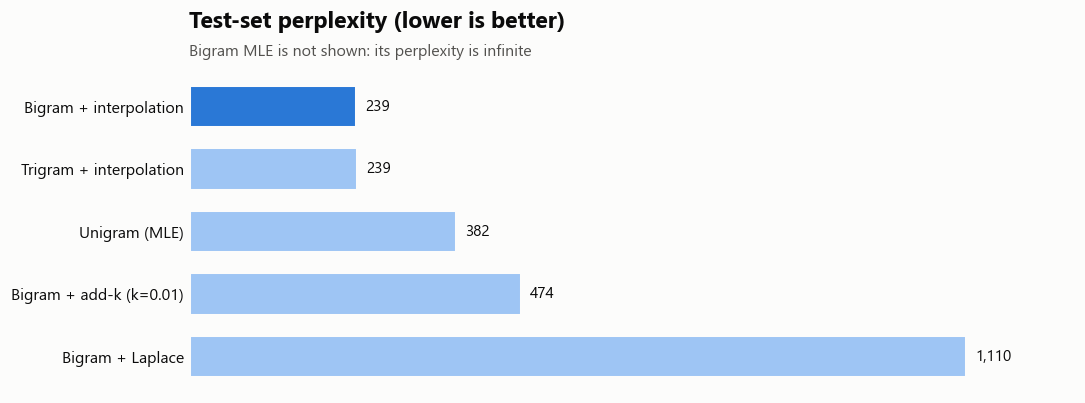

In [13]:
finite = results[results != float("inf")].sort_values()
fig, ax = plt.subplots(figsize=(10, 3.8))
hbar(ax, finite.index, finite.values, fmt="{:,.0f}", color=BLUE_LIGHT, highlight=finite.idxmin())
titles(ax, "Test-set perplexity (lower is better)", "Bigram MLE is not shown: its perplexity is infinite")
plt.tight_layout()
plt.show()

## Conclusion
We implemented unigram, bigram and trigram language models from counts and used them to score sentences with the chain rule. MLE gives zero probability to any sentence with an unseen N-gram, so the unsmoothed bigram model has **infinite perplexity** on new text. We implemented three smoothing methods to fix this:
- **Laplace (add-one)** removes the zeros but takes far too much probability from seen bigrams, so it has the highest perplexity, worse even than the unigram model.
- **Add-k** with a small k (k = 0.01, chosen on the development set) more than halves Laplace's perplexity.
- **Linear interpolation** mixes bigram (or trigram) estimates with unigram estimates and gives the lowest perplexity of all.

The interpolated trigram model is no better than the interpolated bigram model here: with only about 3,700 training sentences, most trigrams are seen too rarely to add information, so the tuned weights give the trigram part only 0.1.